In [1]:
# Importation des bibliothèques et modules du projet
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Ajout du dossier src au sys.path local
sys.path.insert(0, str(Path('../src').resolve()))

from simu_lockin_kk.config import RCCircuitConfig, NoiseConfig, LockInConfig, KKConfig
from simu_lockin_kk.physics.rc_circuit import RCCircuit, generate_time_response
from simu_lockin_kk.signal.lockin import demodulate_signal, demodulate_sweep
from simu_lockin_kk.analysis.kramers_kronig import KramersKronigAnalyzer
from simu_lockin_kk.visualization.plots import plot_time_domain, plot_bode, plot_kramers_kronig_comparison

# Configuration graphique globale
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
print("Environnement + modules simu_lockin_kk chargés.")

Environnement + modules simu_lockin_kk chargés.


Résistance R        : 1000.0 Ω
Capacité C          : 1.00 µF
Constante de temps τ: 1.000 ms
Fréquence coupure fc: 159.15 Hz


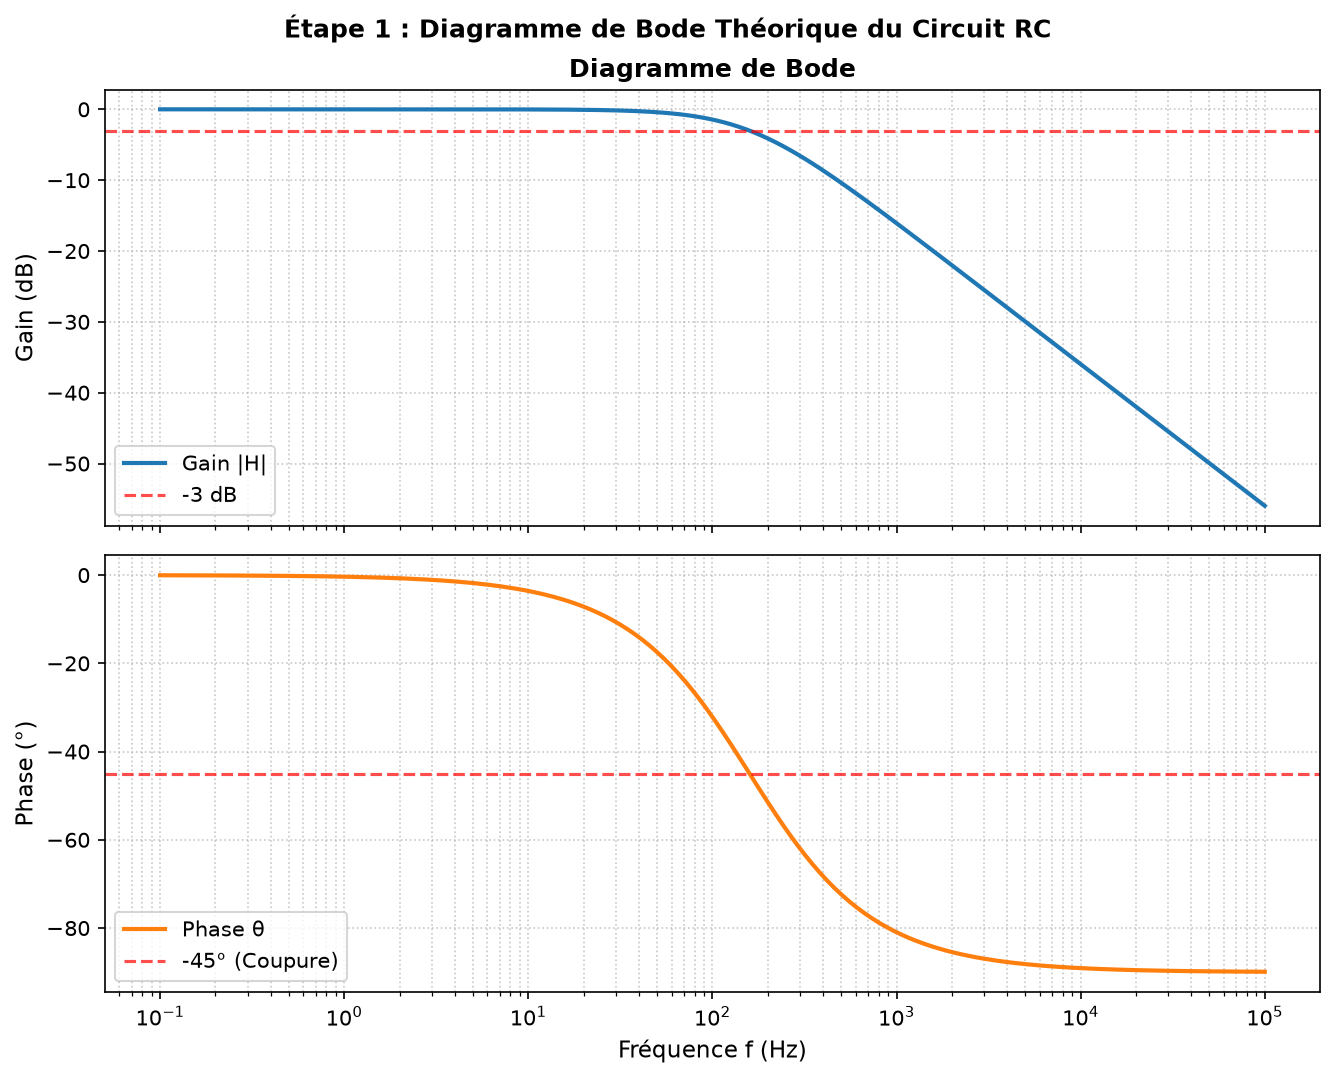

In [2]:
# 1. Configuration physique
rc_cfg = RCCircuitConfig(R=1000.0, C=1e-6, num_freqs=150, f_min=0.1, f_max=1e5)
circuit = RCCircuit(rc_cfg)

print(f"Résistance R        : {circuit.R:.1f} Ω")
print(f"Capacité C          : {circuit.C*1e6:.2f} µF")
print(f"Constante de temps τ: {circuit.tau*1e3:.3f} ms")
print(f"Fréquence coupure fc: {circuit.fc:.2f} Hz")

# 2. Récupération du spectre théorique analytique
spectrum_theo = circuit.get_spectrum()

# 3. Affichage intermédiaire : Diagramme de Bode Théorique
fig_bode_theo = plot_bode(spectrum_theo, use_omega=False)
plt.suptitle("Étape 1 : Diagramme de Bode Théorique du Circuit RC", y=1.02, fontweight='bold')
plt.show()

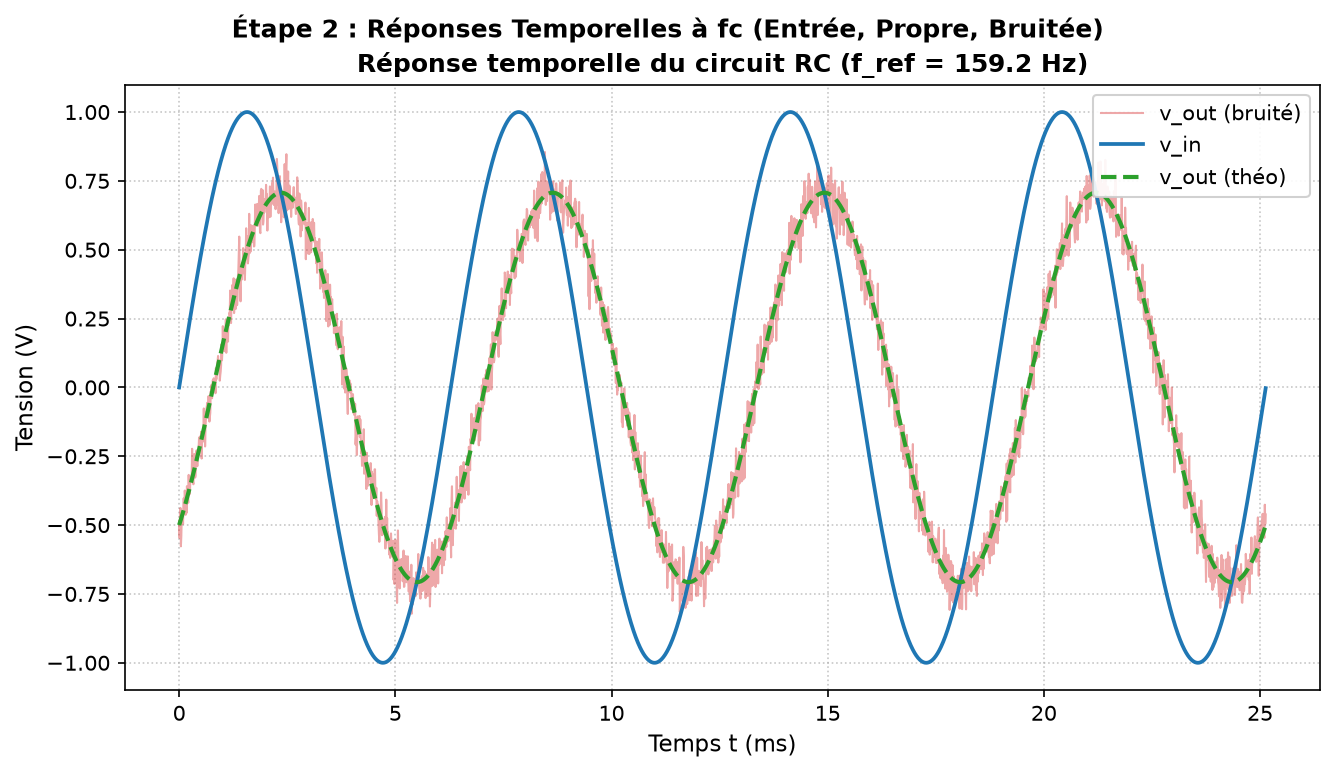

In [3]:
f_target = circuit.fc  # Fréquence de coupure fc
noise_cfg = NoiseConfig(noise_type="white", std_white=0.05, seed=42)

# Génération des signaux temporels
time_data = generate_time_response(
    config=rc_cfg,
    f_ref=f_target,
    duration=0.04,
    fs=1e5,
    noise_cfg=noise_cfg
)

# Affichage intermédiaire : Signal temporel d'excitation vs sortie bruitée
fig_time = plot_time_domain(time_data, num_periods=4.0)
plt.suptitle("Étape 2 : Réponses Temporelles à fc (Entrée, Propre, Bruitée)", y=1.02, fontweight='bold')
plt.show()

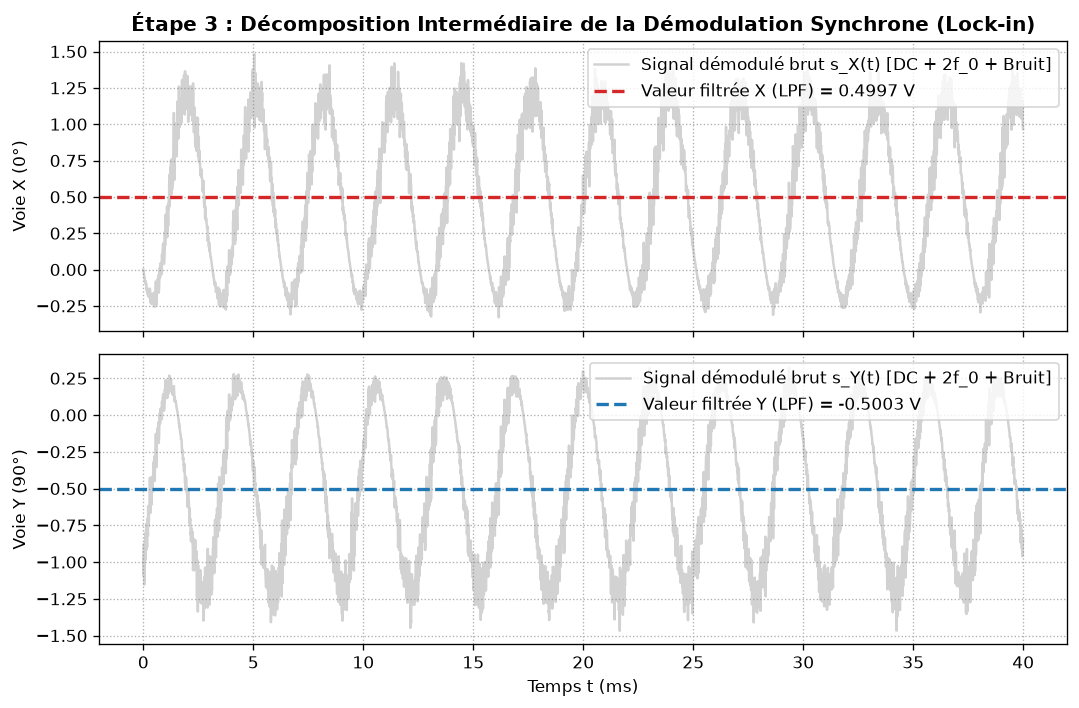

--- Bilan de la démodulation à f = 159.15 Hz ---
X (Réel) mesuré  : 0.4997 V  | Théorique : 0.5000 V
Y (Imag) mesuré  : -0.5003 V | Théorique : -0.5000 V
Amplitude R      : 0.7071 V  | Théorique : 0.7071 V
Phase θ          : -45.03°   | Théorique : -45.00°


In [4]:
t = time_data.t
v_noisy = time_data.v_out_noisy
w0 = 2.0 * np.pi * f_target

# 1. Multiplication PSD par la référence local 0° et 90°
s_X = v_noisy * (2.0 * np.sin(w0 * t))
s_Y = v_noisy * (2.0 * np.cos(w0 * t))

# 2. Extraction du résultat démodulé après filtrage passe-bas (LPF)
lockin_cfg = LockInConfig(f_ref=f_target, lpf_cutoff=10.0, lpf_order=2)
X_meas, Y_meas, R_meas, phase_meas = demodulate_signal(t, v_noisy, f_ref=f_target, lockin_cfg=lockin_cfg)

# 3. Affichage graphique des étapes internes de la démodulation synchrone
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
t_ms = t * 1e3

# Voie X (En phase)
ax1.plot(t_ms, s_X, color='gray', alpha=0.35, label='Signal démodulé brut s_X(t) [DC + 2f_0 + Bruit]')
ax1.axhline(X_meas, color='#d62728', linewidth=2.0, linestyle='--', label=f'Valeur filtrée X (LPF) = {X_meas:.4f} V')
ax1.set_ylabel('Voie X (0°)')
ax1.set_title('Étape 3 : Décomposition Intermédiaire de la Démodulation Synchrone (Lock-in)', fontweight='bold')
ax1.grid(True, linestyle=':')
ax1.legend(loc='upper right')

# Voie Y (En quadrature)
ax2.plot(t_ms, s_Y, color='gray', alpha=0.35, label='Signal démodulé brut s_Y(t) [DC + 2f_0 + Bruit]')
ax2.axhline(Y_meas, color='#1f77b4', linewidth=2.0, linestyle='--', label=f'Valeur filtrée Y (LPF) = {Y_meas:.4f} V')
ax2.set_xlabel('Temps t (ms)')
ax2.set_ylabel('Voie Y (90°)')
ax2.grid(True, linestyle=':')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(f"--- Bilan de la démodulation à f = {f_target:.2f} Hz ---")
print(f"X (Réel) mesuré  : {X_meas:.4f} V  | Théorique : 0.5000 V")
print(f"Y (Imag) mesuré  : {Y_meas:.4f} V | Théorique : -0.5000 V")
print(f"Amplitude R      : {R_meas:.4f} V  | Théorique : 0.7071 V")
print(f"Phase θ          : {np.degrees(phase_meas):.2f}°   | Théorique : -45.00°")

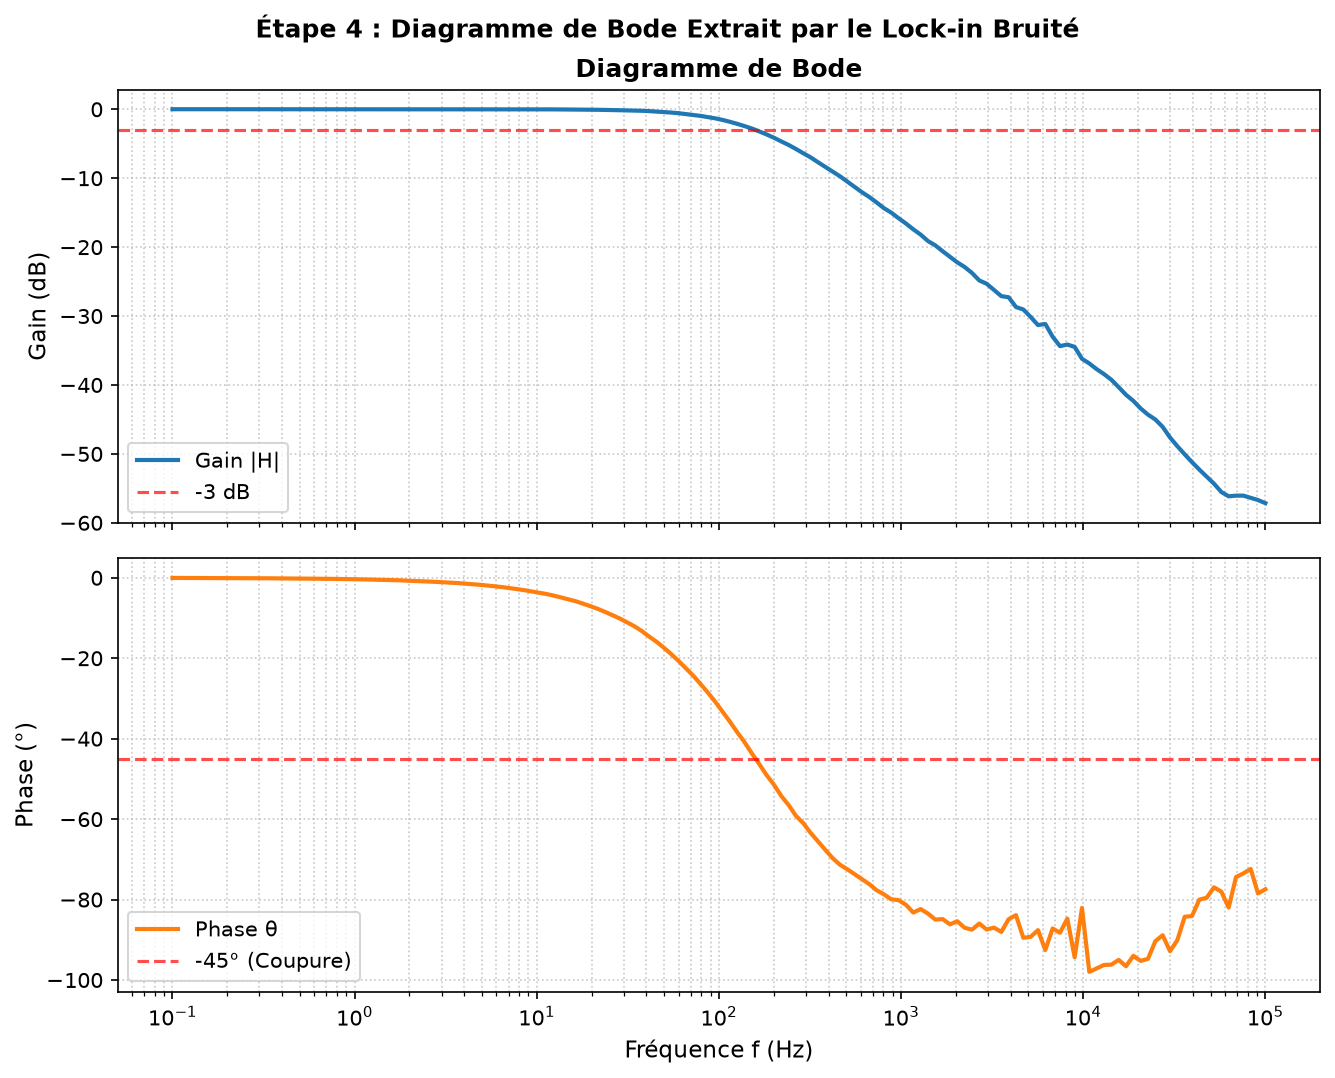

In [5]:
# Balayage fréquentiel simulé
spectrum_lockin = demodulate_sweep(
    rc_config=rc_cfg,
    duration=0.04,
    fs=1e5,
    noise_cfg=noise_cfg,
    lpf_cutoff=10.0,
    lpf_order=2
)

# Diagramme de Bode expérimental mesuré
fig_bode_exp = plot_bode(spectrum_lockin, use_omega=False)
plt.suptitle("Étape 4 : Diagramme de Bode Extrait par le Lock-in Bruité", y=1.02, fontweight='bold')
plt.show()

=== RÉSULTATS DE LA VALIDATION KRAMERS-KRONIG ===
Composante reconstruite : real
Erreur RMS relative     : 1.9116e-03
Score R² (détermination): 0.99998


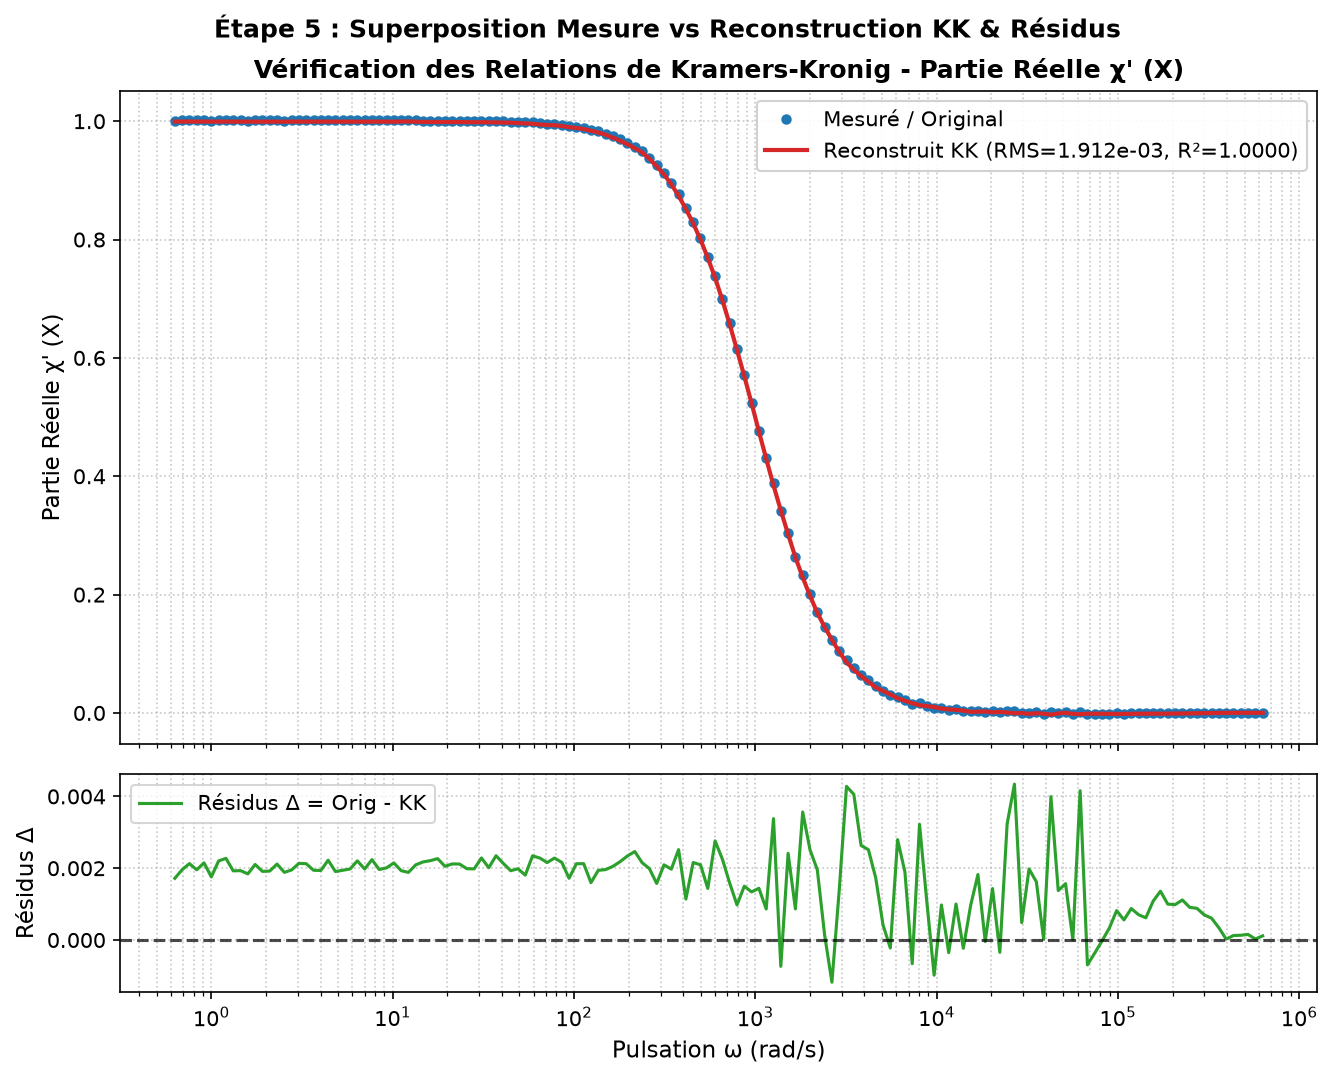

In [6]:
# 1. Analyse Kramers-Kronig (Cauchy-Maclaurin + Extrapolation Asymptotique)
kk_cfg = KKConfig(integration_method="cauchy_maclaurin", extrapolation="asymptotic")
kk_analyzer = KramersKronigAnalyzer(kk_cfg)
kk_result = kk_analyzer.analyze(spectrum_lockin, target="real")

# 2. Métriques globales
print("=== RÉSULTATS DE LA VALIDATION KRAMERS-KRONIG ===")
print(f"Composante reconstruite : {kk_result.target_component}")
print(f"Erreur RMS relative     : {kk_result.rms_error:.4e}")
print(f"Score R² (détermination): {kk_result.r2_score:.5f}")

# 3. Superposition et courbe des résidus
fig_kk = plot_kramers_kronig_comparison(kk_result, use_omega=True)
plt.suptitle("Étape 5 : Superposition Mesure vs Reconstruction KK & Résidus", y=1.02, fontweight='bold')
plt.show()


=== COMPARAISON AVEC / SANS EXTRAPOLATION ===
Avec extrapolation (asymptotic) -> RMS = 1.9116e-03 | R² = 0.99998
Sans extrapolation (none)       -> RMS = 2.6562e-03 | R² = 0.99997


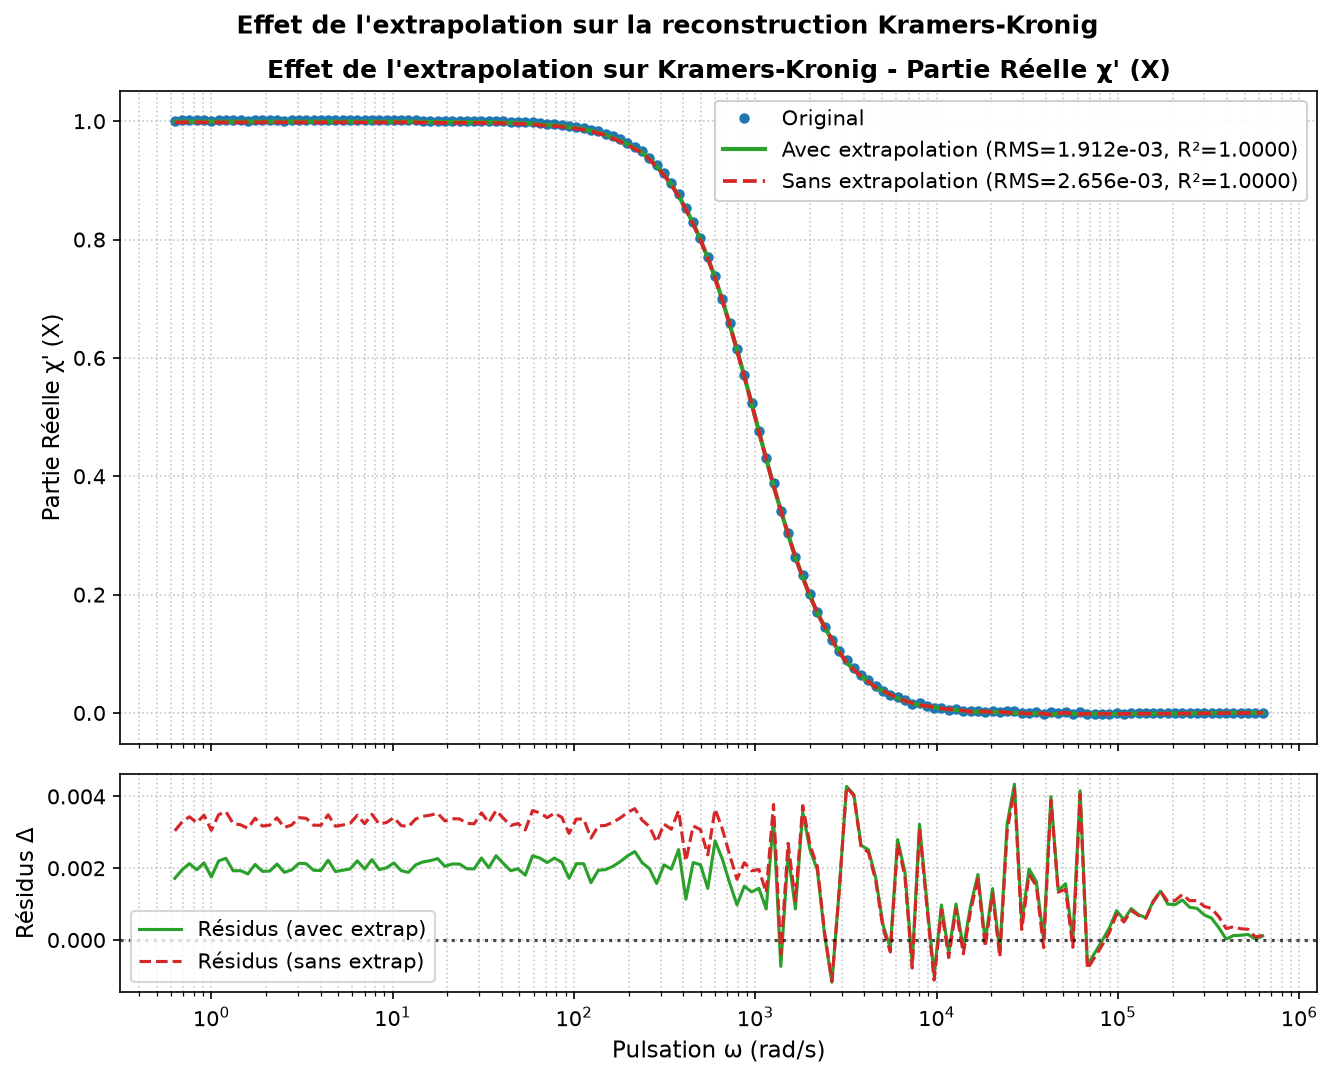

In [7]:
# 4. Analyse Kramers-Kronig SANS extrapolation (pour mesurer l'effet de bord)
from simu_lockin_kk.visualization.plots import plot_extrapolation_comparison


kk_cfg_no_extrap = KKConfig(
    integration_method=kk_cfg.integration_method,
    extrapolation="none",
    singularity_eps=kk_cfg.singularity_eps,
)
kk_result_no_extrap = KramersKronigAnalyzer(kk_cfg_no_extrap).analyze(
    spectrum_lockin,
    target=kk_result.target_component,
)

# 5. Comparaison chiffrée : Avec vs Sans extrapolation
print("\n=== COMPARAISON AVEC / SANS EXTRAPOLATION ===")
print(f"Avec extrapolation ({kk_cfg.extrapolation}) -> RMS = {kk_result.rms_error:.4e} | R² = {kk_result.r2_score:.5f}")
print(f"Sans extrapolation (none)       -> RMS = {kk_result_no_extrap.rms_error:.4e} | R² = {kk_result_no_extrap.r2_score:.5f}")

# 6. Graphique comparatif (avec extrapolation vs sans extrapolation + résidus)
fig_extrap = plot_extrapolation_comparison(
    (kk_result, kk_result_no_extrap),
    use_omega=True,
)
plt.suptitle("Effet de l'extrapolation sur la reconstruction Kramers-Kronig", y=1.02, fontweight="bold")
plt.show()

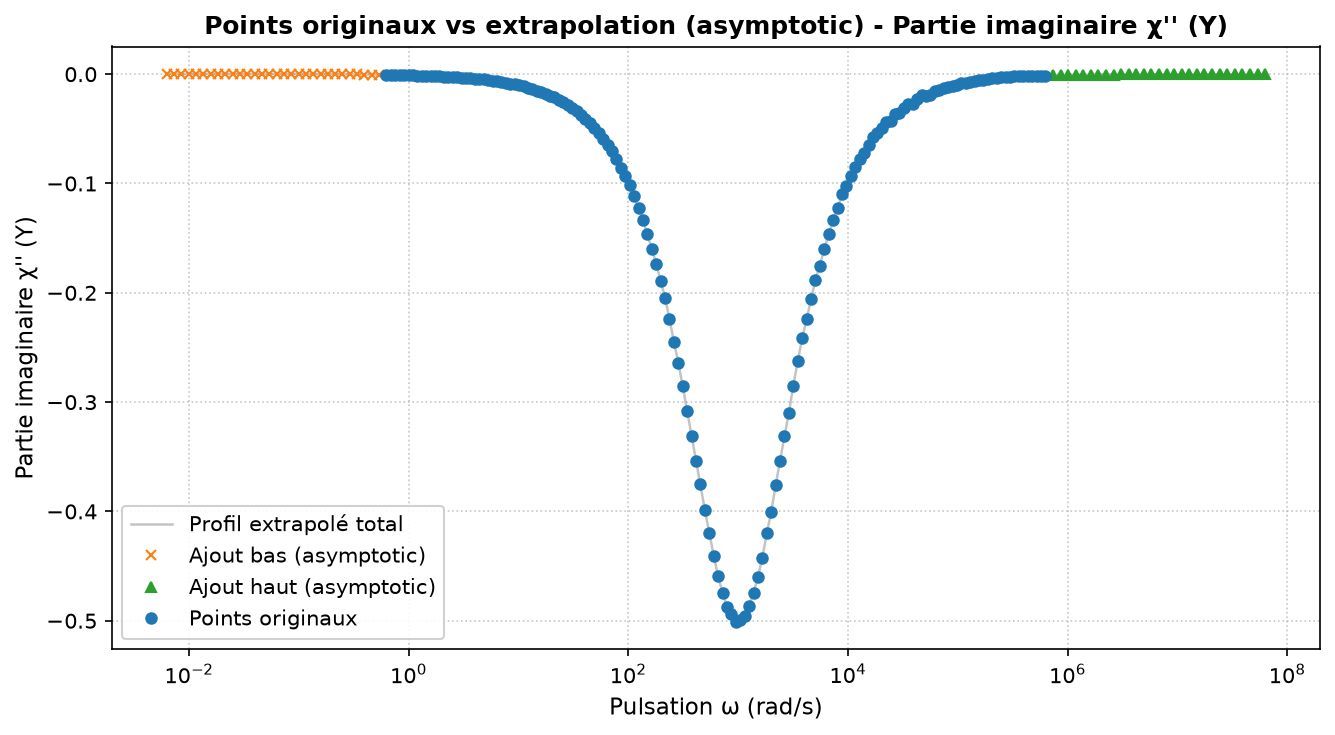

In [8]:
from simu_lockin_kk.visualization.plots import plot_extrapolated_points

fig_pts = plot_extrapolated_points(spectrum_lockin, component="imag", kk_cfg=kk_cfg, use_omega=True)
plt.show()